<a href="https://colab.research.google.com/github/etorrey-vc/CMPU-250/blob/main/Torrey_Assignment_2_%7C_CMPU_250.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<abbr>CMPU</abbr>&thinsp;250 · Assignment 2

# Guidelines

- All data used in this assignment should only be downloaded **from Moodle**.

- Show the code you used to arrive at your answer.

- If you're unsure about your code, make a markdown cell and explain your logic. Even if you get the answer wrong, I may give you points for your explanation.

- Write good, readable code [according to Python style](https://peps.python.org/pep-0008/). You'll be graded in part on the formatting of your code.

- Points are assigned based on expected difficulty and expected length of time it takes to do each problem. "Challenge" problems are required, but will be less points because they're meant to challenge you. "Extra Credit" problems are not required.

&nbsp;

# Run this code first

In [1]:
# run this first
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# suppress warnings
pd.options.mode.chained_assignment = None
pd.options.mode.copy_on_write = True


&nbsp;

&nbsp;

# Exercise 1: Movies *(25 points)*

For this exercise, we will be practicing data manipulation. Your task is to examine data about movie profits. For this problem, use the dataset `movies.csv` (available on Moodle).

Here is a description of its contents:
- `release_date`: month-day-year
- `movie`: Movie title
- `production_budget`: Money spent to create film
- `domestic_gross`: Gross revenue from USA
- `worldwide_gross`: Gross revenue worldwide
- `distributor`: Distribution company
- `mpaa_rating`: Age rating in US
- `genre`: Film category

&nbsp;

## Q1 (1 pt)

Load in the data and assign it to the name `movies`.

In [2]:
movies = pd.read_csv("movies.csv")

&nbsp;

## Q2 (2 pts)

Answer the following:
- How many unique movies are in this data set?

&nbsp;

*(Hint: you can use the `.unique()` method. [See documentation](https://pandas.pydata.org/docs/reference/api/pandas.Series.unique.html).)*

**Answer:** [delete this, write your answer here]

In [3]:
unique_movies = movies["movie"].unique()
len(unique_movies)

1747

&nbsp;

## Q3 (4 pts)

- Do the following: Add a new column to your dataframe named `release_year` that contains only the year in `release_date`. *For example, if the value in `release_date` is `6/22/2007`, the value for the same entry in `release_year` should be `2007`.*

- Answer the following: What is the *range* of release years in the data? *In other words, find the maximum and minimum release years.*

**Answer:** The range of release years in the data is 79 years.

In [4]:
movies["release_year"] = [x[-4:] for x in movies["release_date"]]
movies["release_year"]


,release_year
0,2007
1,1995
2,2017
3,2013
4,2018
...,...
1742,2015
1743,1964
1744,2009
1745,2003


In [5]:
release_year_range = int(movies["release_year"].max()) - int(movies["release_year"].min())

print("Most recent movie: " + movies["release_year"].max())
print("Least recent movie: " + movies["release_year"].min())
print("Range of movie release years: " + str(release_year_range))

Most recent movie: 2019
Least recent movie: 1940
Range of movie release years: 79


&nbsp;

## Q4 (3 pts)

- Do the following: Add a new column to your dataframe named `net_profit`, which is the elementwise (i.e., per movie) sum of `domestic_gross` plus `worldwide_gross` minus `production_budget`. *For example, if a movie's domestic gross was 100.3, its worldwide gross was 174.1, and its production budget was 175.0, the net profit for this movie should be 99.4.*

- Answer the following: What were the five most profitable movies in this dataset?

**Answer:** The five most profitable movies were Jurassic World: Fallen Kingdom, Minions, Star Wars Ep. I: The Phantom Menace, Jurassic Park, and The Lion King.

In [7]:
movies["net_profit"] = movies["domestic_gross"] + movies["worldwide_gross"] - movies["production_budget"]
movies.sort_values("net_profit",ascending=False).head(5)

,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre,release_year,net_profit
4,6/22/2018,Jurassic World: Fallen Kingdom,170.0,416.8,1304.9,Universal,PG-13,Action,2018,1551.7
379,7/10/2015,Minions,74.0,336.0,1162.8,Universal,PG,Adventure,2015,1424.8
142,5/19/1999,Star Wars Ep. I: The Phantom Menace,115.0,474.5,1027.0,Fox,PG,Adventure,1999,1386.5
479,6/11/1993,Jurassic Park,63.0,395.7,1038.8,Universal,PG-13,Action,1993,1371.5
341,6/15/1994,The Lion King,79.3,421.8,986.3,Disney,G,Adventure,1994,1328.8


&nbsp;

## Q5 (2 pts)

How many movies in this data lost money (`net_profit < 0`)?

**Answer:** 186 movies lost money.

In [8]:
len([x for x in movies["net_profit"] if x < 0])


186

&nbsp;

## Q6 (3 pts)

Let's see which movies got the most "bang for its buck," i.e., which earned a high profit for each dollar of their production budget.

- Do the following: Make a new column called `rpd` (for Return Per Dollar), which is `net_profit` divided by `production_budget`, per movie.

- Answer the following: Which five movies did best in terms of Return Per Dollar? (Display them in your code.)

**Answer:** The top performing movies in Return Per Dollar are Paranormal Activity, American Graffiti, The Devil Inside, ET: The Extra-Terrestrial, and Star Wars Ep. IV: A New Hope

In [11]:
movies["rpd"] = movies["net_profit"] / movies ["production_budget"]
movies.sort_values("rpd",ascending=False).head(5)

,release_date,movie,production_budget,domestic_gross,worldwide_gross,distributor,mpaa_rating,genre,release_year,net_profit,rpd
1744,9/25/2009,Paranormal Activity,0.450,107.9,194.2,Paramount,R,Horror,2009,301.650,670.333333
1741,8/11/1973,American Graffiti,0.777,115.0,140.0,Universal,PG,Drama,1973,254.223,327.185328
1737,1/6/2012,The Devil Inside,1.000,53.3,101.8,Paramount,R,Horror,2012,154.100,154.100000
1573,6/11/1982,ET: The Extra-Terrestrial,10.500,435.1,793.0,Universal,PG,Drama,1982,1217.600,115.961905
1553,5/25/1977,Star Wars Ep. IV: A New Hope,11.000,461.0,786.6,Fox,PG,Adventure,1977,1236.600,112.418182


&nbsp;

## Q7 (10 pts)

Do the following: Use the `groupby()` function to display the mean `'net_profit'`, the mean `'production_budget'`, and the mean return per dollar (`rpd`) grouped by `genre`.

Then, look at [this article](https://www.statsignificant.com/p/why-horror-films-are-hollywoods-best), and comment on whether your analysis seems to corroborate Hickey’s result or not.

**Answer:** My analysis corroborates Hickey's result because although horror movies have noticably low budget in comparison to other genres, their net profit is still competitive. Ensuingly, they boast a significantly higher return per dollar than other genres.

In [13]:
movies.groupby("genre")[["net_profit","production_budget","rpd"]].mean()

,net_profit,production_budget,rpd
genre,,,
Action,213.918713,72.807895,3.342686
Adventure,267.430057,69.388175,4.993981
Comedy,114.286855,33.747419,5.106459
Drama,102.309879,35.648526,5.006496
Horror,132.882415,26.361653,18.409754



&nbsp;

# Exercise 2: Election *(25 points)*

For this exercise, the dataset `minneapolis_mayor_votes_2013.csv` is available on Moodle. Your task is to clean and prepare this data, then do some analysis.

Each row of this data represents a single voter's ballot in the 2013 Minneapolis mayoral election. Minneapolis has ranked choice voting, which means each ballot has up to three candidate names ranked from 1st to 3rd.

Here is a description of the columns of this data as it's loaded in:
- `Precinct`: which polling precinct
- `1ST CHOICE MAYOR MINNEAPOLIS`: the candidate ranked first
- `2ND CHOICE MAYOR MINNEAPOLIS`: the candidate ranked second
- `3RD CHOICE MAYOR MINNEAPOLIS`: the candidate ranked third
- `COUNT`: how much each vote counts for

Read more about this data [here](https://vote.minneapolismn.gov/results-data/election-results/2013/mayor/) and ranked choice voting [here](https://vote.minneapolismn.gov/ranked-choice-voting/how-we-count-rcv-ballots/).

&nbsp;

## Q1 (2 pts)

Load in the data, assign it to the name `mayor`, and **save a copy of the original.**

In [14]:
mayor = pd.read_csv("minneapolis_mayor_votes_2013.csv")
mayor

,Precinct,1ST CHOICE MAYOR MINNEAPOLIS,2ND CHOICE MAYOR MINNEAPOLIS,3RD CHOICE MAYOR MINNEAPOLIS,COUNT
0,MINNEAPOLIS W-7 P-10,BETSY HODGES,undervote,undervote,1
1,MINNEAPOLIS W-10 P-06,BOB FINE,MARK ANDREW,undervote,1
2,MINNEAPOLIS W-10 P-09,KURTIS W. HANNA,BOB FINE,MIKE GOULD,1
3,MINNEAPOLIS W-13 P-05,BETSY HODGES,DON SAMUELS,undervote,1
4,MINNEAPOLIS W-5 P-01,DON SAMUELS,undervote,undervote,1
...,...,...,...,...,...
80096,MINNEAPOLIS W-9 P-06,BETSY HODGES,JACKIE CHERRYHOMES,MARK ANDREW,1
80097,MINNEAPOLIS W-10 P-02,MARK ANDREW,DON SAMUELS,DOUG MANN,1
80098,MINNEAPOLIS W-8 P-07,MARK ANDREW,BETSY HODGES,DON SAMUELS,1
80099,MINNEAPOLIS W-4 P-04,MARK ANDREW,BETSY HODGES,undervote,1


&nbsp;

## Q2 (3 pts)

Let's clean the column labels. To do so, do the following:
- Change all column labels to title case.
- Rename the middle three columns to `Rank 1`, `Rank 2`, and `Rank 3`.
- Drop any columns that contain only a single unique value.

After these steps, print your dataframe.

In [15]:
mayor.columns = ["Precinct","Rank 1","Rank 2","Rank 3","Count"]
mayor = mayor.drop(columns="Count")

In [ ]:
print(mayor)

                    Precinct           Rank 1               Rank 2  \
0       MINNEAPOLIS W-7 P-10     BETSY HODGES            undervote   
1      MINNEAPOLIS W-10 P-06         BOB FINE          MARK ANDREW   
2      MINNEAPOLIS W-10 P-09  KURTIS W. HANNA             BOB FINE   
3      MINNEAPOLIS W-13 P-05     BETSY HODGES          DON SAMUELS   
4       MINNEAPOLIS W-5 P-01      DON SAMUELS            undervote   
...                      ...              ...                  ...   
80096   MINNEAPOLIS W-9 P-06     BETSY HODGES   JACKIE CHERRYHOMES   
80097  MINNEAPOLIS W-10 P-02      MARK ANDREW          DON SAMUELS   
80098   MINNEAPOLIS W-8 P-07      MARK ANDREW         BETSY HODGES   
80099   MINNEAPOLIS W-4 P-04      MARK ANDREW         BETSY HODGES   
80100  MINNEAPOLIS W-13 P-09      MARK ANDREW  JEFFREY ALAN WAGNER   

            Rank 3  
0        undervote  
1        undervote  
2       MIKE GOULD  
3        undervote  
4        undervote  
...            ...  
80096  MARK 

&nbsp;

## Q3 (3 pts)

Let's clean the text columns. To do so, do the following:
- Remove any instance of `'MINNEAPOLIS'` or `'Minneapolis'` from all entries in the dataframe.
- Remove any leading or trailing whitespace from all strings.
- Remove all special characters from all strings. *Note: Special characters are anything that isn't in the English alphabet (letters A through Z) or numbers 0 through 9.*
- Change all names of people in the dataframe to title case. *(You can change `'undervote'` and `'overvote'` to title case if you want --- you can also leave it as lower case.)*

After these steps, print your dataframe.

In [16]:
# Minneapolis instances
mayor["Precinct"] = mayor["Precinct"].str.replace("Minneapolis",'',case=False)
# whitespace
mayor = mayor.map(lambda x: x.strip())
# special chars
mayor = mayor.map(lambda y: re.sub(r'[^a-zA-Z0-9 ]', '', y))
# title case
mayor["Rank 1"] = mayor["Rank 1"].str.title()
mayor["Rank 2"] = mayor["Rank 2"].str.title()
mayor["Rank 3"] = mayor["Rank 3"].str.title()
mayor

,Precinct,Rank 1,Rank 2,Rank 3
0,W7 P10,Betsy Hodges,Undervote,Undervote
1,W10 P06,Bob Fine,Mark Andrew,Undervote
2,W10 P09,Kurtis W Hanna,Bob Fine,Mike Gould
3,W13 P05,Betsy Hodges,Don Samuels,Undervote
4,W5 P01,Don Samuels,Undervote,Undervote
...,...,...,...,...
80096,W9 P06,Betsy Hodges,Jackie Cherryhomes,Mark Andrew
80097,W10 P02,Mark Andrew,Don Samuels,Doug Mann
80098,W8 P07,Mark Andrew,Betsy Hodges,Don Samuels
80099,W4 P04,Mark Andrew,Betsy Hodges,Undervote


In [17]:
print(mayor)

      Precinct          Rank 1               Rank 2       Rank 3
0       W7 P10    Betsy Hodges            Undervote    Undervote
1      W10 P06        Bob Fine          Mark Andrew    Undervote
2      W10 P09  Kurtis W Hanna             Bob Fine   Mike Gould
3      W13 P05    Betsy Hodges          Don Samuels    Undervote
4       W5 P01     Don Samuels            Undervote    Undervote
...        ...             ...                  ...          ...
80096   W9 P06    Betsy Hodges   Jackie Cherryhomes  Mark Andrew
80097  W10 P02     Mark Andrew          Don Samuels    Doug Mann
80098   W8 P07     Mark Andrew         Betsy Hodges  Don Samuels
80099   W4 P04     Mark Andrew         Betsy Hodges    Undervote
80100  W13 P09     Mark Andrew  Jeffrey Alan Wagner   Mike Gould

[80101 rows x 4 columns]


&nbsp;

## Q4 (7 pts)

First, answer the following:
- Who got the most round 1 (rank 1) votes?
- How many total round 1 votes did they receive?
- What percentage of round 1 votes did they receive?

Second, make and display two bar plots --- one with the count of round 1 votes and another plot with the percentage of round 1 votes that each candidate received.

*Note: You should sort the counts and percentages before you plot them.*

**Answer:** The most round 1 votes were for Betsy Hodges, who earned 28,935 votes. This represented 36.12% of the total round 1 votes.

In [18]:
r1_count = mayor.groupby("Rank 1").size().sort_values(ascending=False)
r1_count
(28935/80101)*100

36.123144530030835

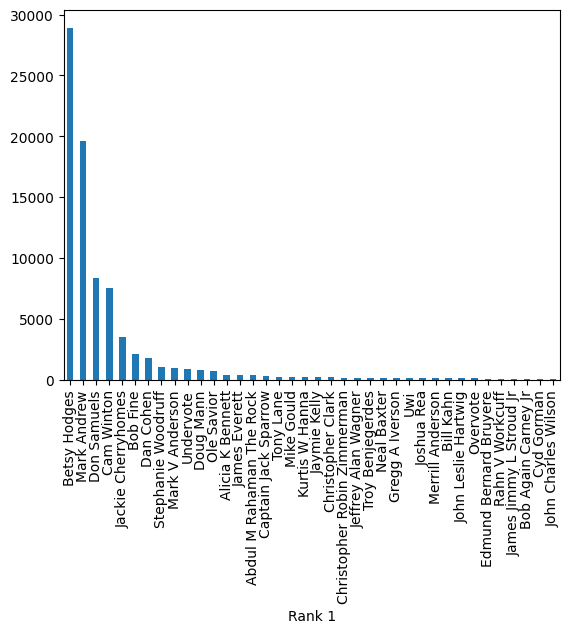

In [20]:
r1_count.plot.bar()
plt.show()

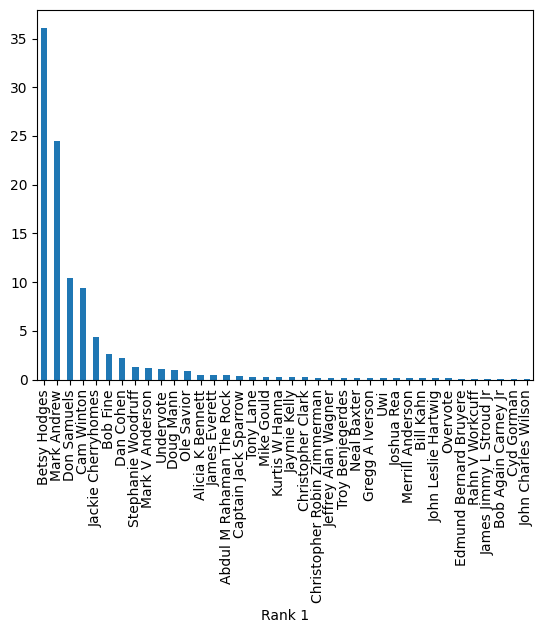

In [21]:
r1_percents = (r1_count / r1_count.sum()) * 100
r1_percents.plot.bar()
plt.show()

&nbsp;

## Q5 (10 pts)

There's some invalid votes in round 1 that are distorting the percentage of votes that each candidate received. Do the following:

  1. Answer: How many overvotes and undervotes were there in round 1?

  2. There's at least one candidate in the data who shares a name with a fictional character. Who is it? How many round 1 votes did they receive? *(Note: You have to manually look at the names of candidates to find this person.)*

  3. Make a new column named `Rank 1 Valid` that contains boolean values (`True` or `False`) indicating whether a round 1 (rank 1) vote was valid or not.

- Follow this criteria:
  - Overvotes and undervotes are invalid.

  - You decide whether votes for the person with the name of a fictional character is valid or not --- in your answer below, <u>give your reasoning as to why you think these votes are valid or not.</u> (Note: There's no right or wrong answer here, just explain yourself.)

  - All other votes are valid.


4. Based on your new `Rank 1 Valid` column, what percentage of *valid* votes did the leading candidate receive in round 1 of tabulation?

**Answer:**

    1) There were 927 total Overvotes and Undervotes in round 1.

    2) Captain Jack Sparrow received 264 votes.

    3) Votes for fictional characters are valid, because the goal of democracy is to allow the people to decide how to be governed. Should they vote for a fictional character, so be it. There was a [dog](https://en.wikipedia.org/wiki/Mayor_Max_II) who was a local mayor in California for like 9 years. He is succeeded by his cousin. Who is also a dog.

    4) Betsy Hodges received 36.55% of valid votes.

In [22]:
i = 0
for x in mayor["Rank 1"]:
    if x == "Overvote" or x == "Undervote":
        i += 1
print(i)

mayor["Rank 1 Valid"] = [not(x == "Overvote" or x == "Undervote") for x in mayor["Rank 1"]]

mayor.groupby("Rank 1 Valid").size().sort_values(ascending=False)
only_valid = mayor[mayor["Rank 1 Valid"]]

only_valid.groupby("Rank 1").size().sort_values(ascending=False)

betsy_percent_of_valids = (len(mayor[mayor["Rank 1"] == "Betsy Hodges"]) / len(only_valid)) * 100
betsy_percent_of_valids



927


36.54608836234117

&nbsp;

## Q6 (Extra Credit, 3 pts)

Write code to tabulate votes according to Minneapolis' RCV tabulation process. Read about this process here: https://vote.minneapolismn.gov/ranked-choice-voting/how-we-count-rcv-ballots/.

Then, answer the following:

  1. Who won the election?

  2. By what margin?

  3. How many votes did each candidate get?

**Answer:** [delete this, write your answer here]

In [ ]:
# delete this comment, write your code here